# Training-data exploration

CM2604 Coursework 1, Part 01. This notebook describes the training customers before preprocessing or modelling. It exports aggregate tables and figures for later report writing. No customer-level rows or identifiers are displayed.

## Method

The validated original CSV is split once using `test_size=0.2`, `random_state=42` and stratification by churn. Stratification keeps approximately the same class proportions in each partition. A fixed seed reproduces the split when the input row order and software versions are unchanged (scikit-learn developers, n.d.). All detailed exploration below uses the training partition. The held-out partition is reserved for final evaluation.

Missing charges remain missing in this release. Imputation and scaling will be fitted inside training-fold pipelines in a later release. These descriptive comparisons show associations in this dataset; they do not establish causes or model performance.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").is_file():
    raise RuntimeError("Run this notebook from the repository root or notebooks folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from src.data import CATEGORIES, NUMERIC_COLUMNS, load_data, split_data

FIGURES = ROOT / "outputs" / "figures"
TABLES = ROOT / "outputs" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})
COLORS = ["#31688e", "#d45b39"]
LABELS = {"tenure": "Tenure (months)", "MonthlyCharges": "Monthly charges (dataset units)",
          "TotalCharges": "Total charges (dataset units)"}

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160, metadata={"Software": "Matplotlib"})
    plt.close(fig)
    display(Image(filename=str(FIGURES / name)))

## Fixed split and partition checks

The following checks verify that every row belongs to exactly one partition, labels stay aligned with predictors and repeated splitting returns the same rows. Only partition sizes are exported for the test data.

In [2]:
frame = load_data()
X_train, X_test, y_train, y_test = split_data(frame)
assert not set(X_train.index) & set(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(frame.index)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert "customerID" not in X_train and "Churn" not in X_train
for first, repeated in zip((X_train, X_test, y_train, y_test), split_data(frame)):
    assert first.equals(repeated)
assert abs(y_train.mean() - frame["Churn"].eq("Yes").mean()) < 1 / len(y_train)

split_summary = pd.DataFrame({"partition": ["training", "held_out"],
                              "rows": [len(X_train), len(X_test)],
                              "requested_fraction": [0.8, 0.2], "seed": [42, 42]})
split_summary.to_csv(TABLES / "split_summary.csv", index=False)
display(split_summary)
train = X_train.copy()
train["Churn"] = y_train.map({0: "No", 1: "Yes"})
# Remove access to held-out features after the structural split checks.
del X_test, y_test, frame

,partition,rows,requested_fraction,seed
0,training,5634,0.8,42
1,held_out,1409,0.2,42


## Numeric statistics and missing values

The numeric table reports counts, sample standard deviations and quartiles before imputation. Counts exclude missing values. The missing-value table includes every training predictor and the target. Categorical counts preserve service categories such as "No internet service".

In [3]:
numeric_summary = train[NUMERIC_COLUMNS].describe().T
numeric_summary.index.name = "feature"
numeric_summary.to_csv(TABLES / "train_numeric_summary.csv")
missing = pd.DataFrame({"feature": train.columns,
                        "missing_count": train.isna().sum().to_numpy()})
missing["missing_percent"] = 100 * missing["missing_count"] / len(train)
missing.to_csv(TABLES / "train_missing_values.csv", index=False)
category_rows = []
for feature in CATEGORIES:
    for category, count in train[feature].value_counts().sort_index().items():
        category_rows.append({"feature": feature, "category": category,
                              "count": int(count), "percent": 100 * count / len(train)})
categorical_summary = pd.DataFrame(category_rows)
categorical_summary.to_csv(TABLES / "train_categorical_counts.csv", index=False)
display(numeric_summary.round(2))
display(missing)
blank_charges = train["TotalCharges"].isna()
assert train.loc[blank_charges, "tenure"].eq(0).all()
display(Markdown(f"Training data contain **{int(blank_charges.sum())} missing TotalCharges values**; "
                 "all occur at zero tenure. These rows are retained. Other training fields have "
                 f"{int(train.drop(columns='TotalCharges').isna().sum().sum())} missing values."))

,count,mean,std,min,25%,50%,75%,max
feature,,,,,,,,
tenure,5634.0,32.49,24.57,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,5634.0,64.93,30.14,18.40,35.66,70.50,90.00,118.75
TotalCharges,5626.0,2302.60,2279.17,18.85,407.28,1398.12,3838.61,8684.80


,feature,missing_count,missing_percent
0,gender,0,0.000000
1,SeniorCitizen,0,0.000000
2,Partner,0,0.000000
3,Dependents,0,0.000000
4,tenure,0,0.000000
5,PhoneService,0,0.000000
6,MultipleLines,0,0.000000
7,InternetService,0,0.000000
8,OnlineSecurity,0,0.000000
9,OnlineBackup,0,0.000000


Training data contain **8 missing TotalCharges values**; all occur at zero tenure. These rows are retained. Other training fields have 0 missing values.

## Churn balance

Counts and percentages use the full training partition as their denominator. The class distribution will inform later metric choices; no classifier is evaluated here.

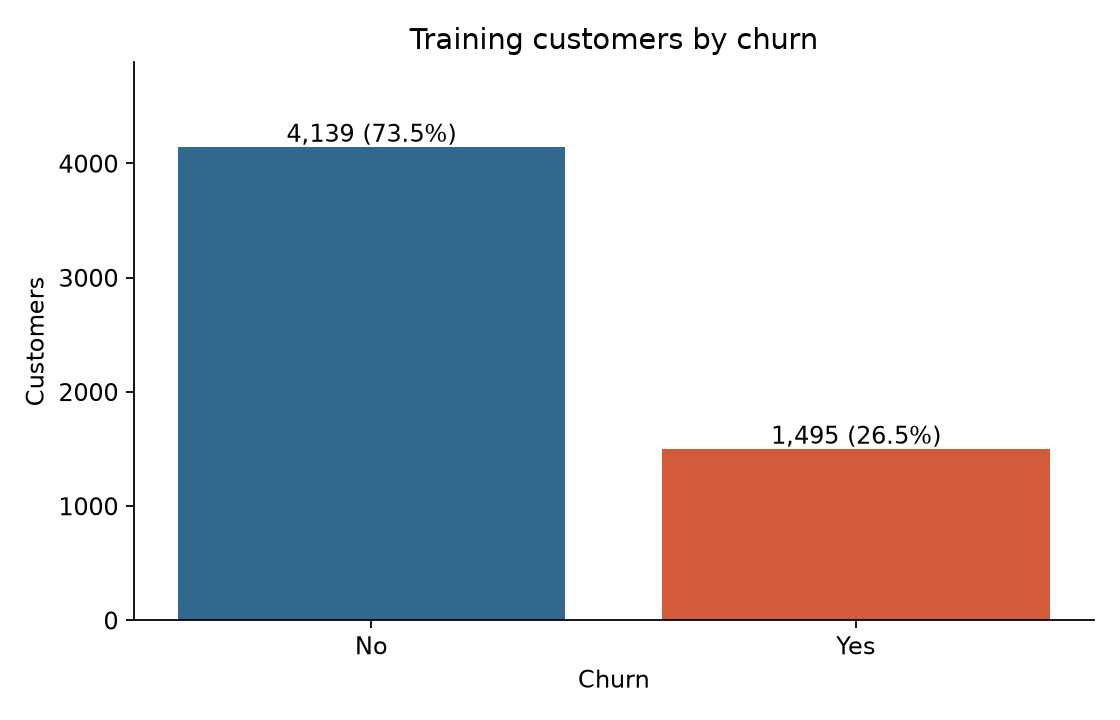

,count,percent
Churn,,
No,4139,73.46
Yes,1495,26.54


26.54% of training customers churned. The No class has 2.77 times as many customers as the Yes class. A later evaluation should therefore report churn precision and recall alongside accuracy.

In [4]:
balance = train["Churn"].value_counts().reindex(["No", "Yes"]).rename_axis("Churn").to_frame("count")
balance["percent"] = 100 * balance["count"] / len(train)
balance.to_csv(TABLES / "train_churn_balance.csv")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(balance.index, balance["count"], color=COLORS)
for label, row in balance.iterrows():
    ax.text(label, row["count"] + 50, f"{int(row['count']):,} ({row['percent']:.1f}%)", ha="center")
ax.set(title="Training customers by churn", xlabel="Churn", ylabel="Customers")
ax.set_ylim(0, balance["count"].max() * 1.18)
save_figure(fig, "train_churn_balance.png")
display(balance.round(2))
display(Markdown(f"{balance.loc['Yes', 'percent']:.2f}% of training customers churned. "
                 f"The No class has {balance.loc['No', 'count'] / balance.loc['Yes', 'count']:.2f} "
                 "times as many customers as the Yes class. A later evaluation should therefore "
                 "report churn precision and recall alongside accuracy."))

## Numeric distributions

Histograms show the observed training values. Missing TotalCharges values are omitted from that histogram only; no customers are removed from the training dataset. Charges are labelled in dataset units because the supplied CSV does not specify a currency.

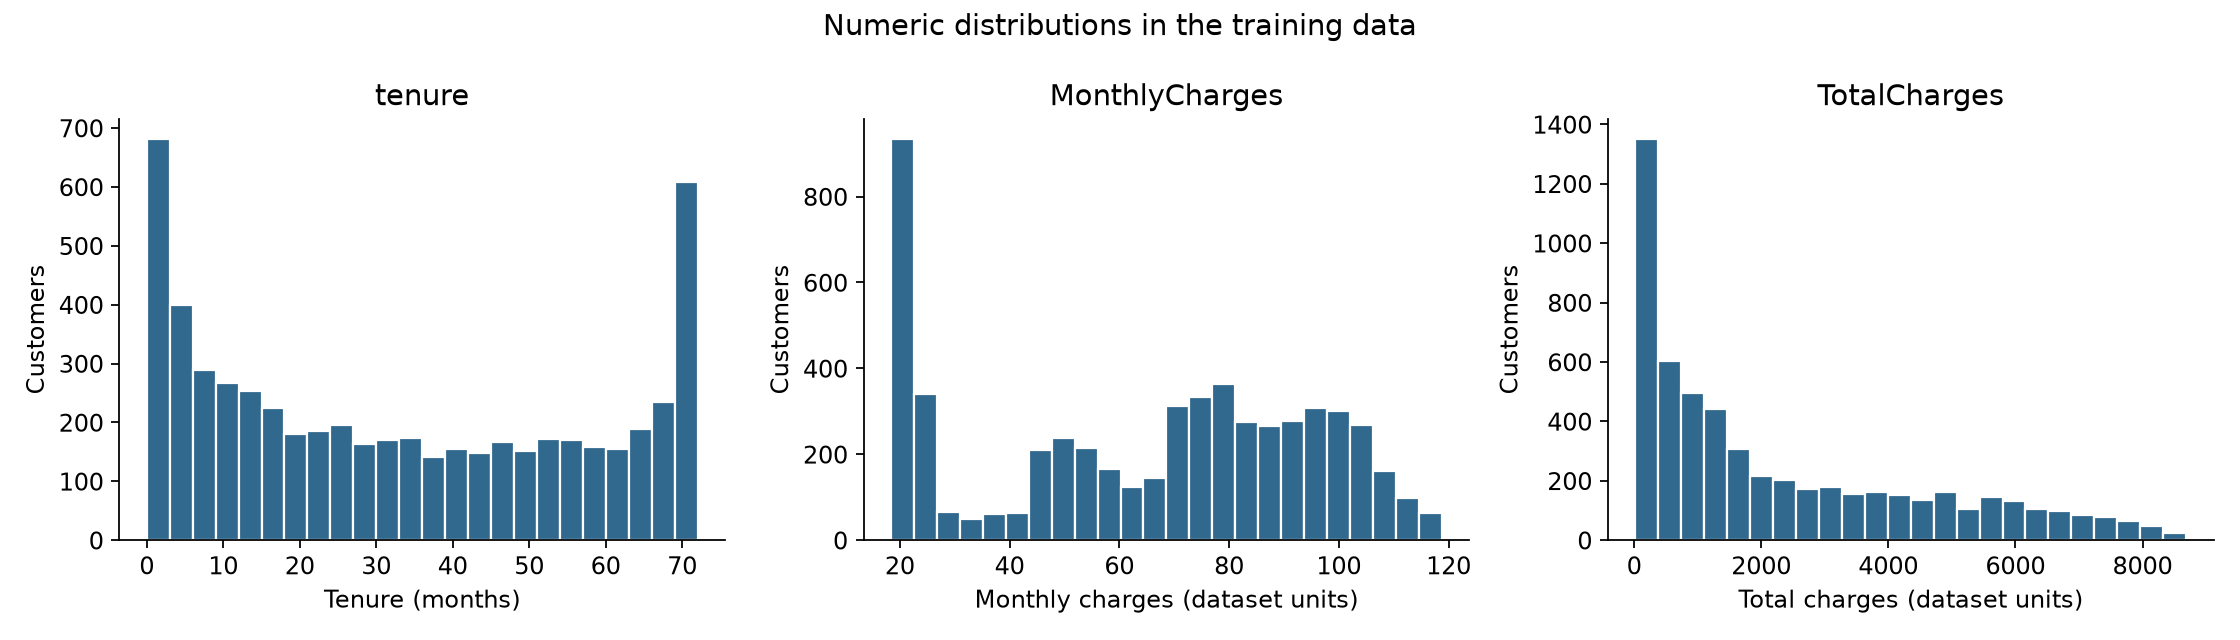

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature in zip(axes, NUMERIC_COLUMNS):
    ax.hist(train[feature].dropna(), bins=24, color=COLORS[0], edgecolor="white")
    ax.set(xlabel=LABELS[feature], ylabel="Customers", title=feature)
fig.suptitle("Numeric distributions in the training data")
save_figure(fig, "train_numeric_distributions.png")

## Contract and churn

Churn rate is the percentage of customers within each contract category whose label is Yes. Group sizes are shown because rates from differently sized groups need that context.

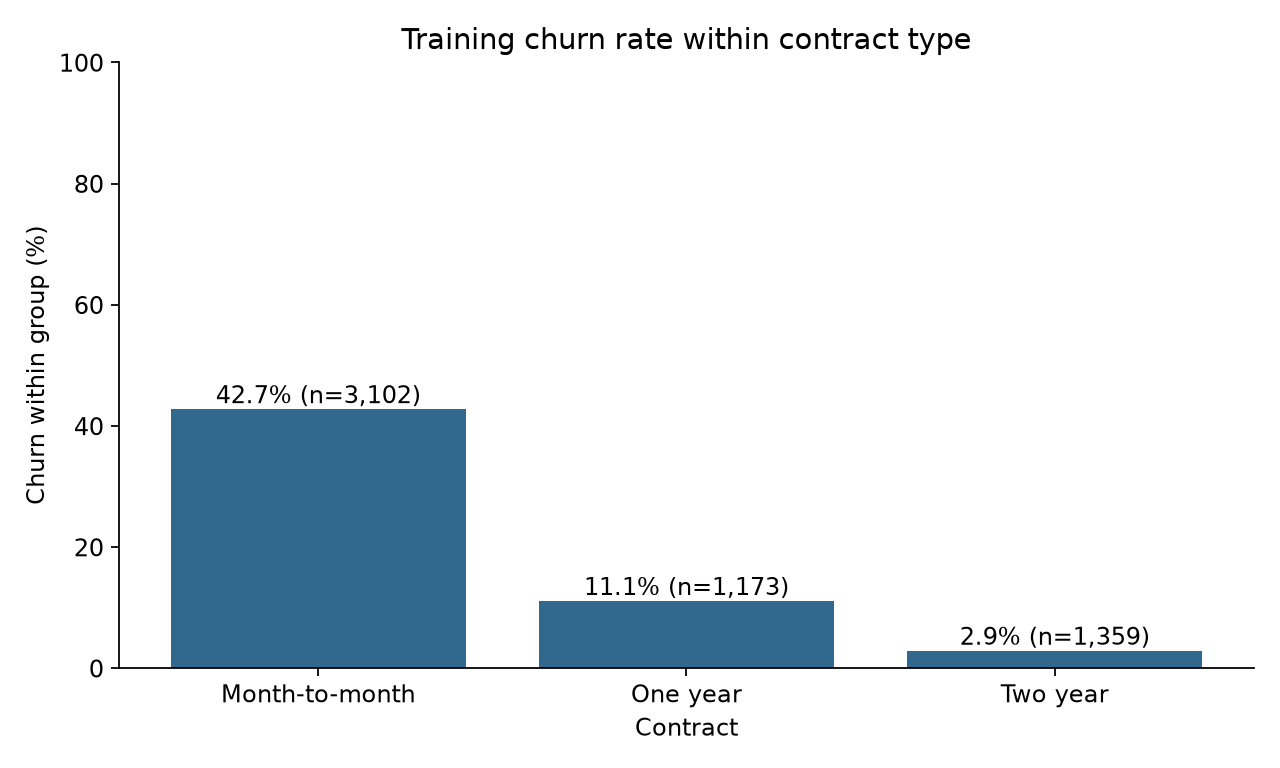

,customers,churned,churn_percent
Contract,,,
Month-to-month,3102,1326,42.75
One year,1173,130,11.08
Two year,1359,39,2.87


Month-to-month customers have the highest observed training churn rate (42.75%), compared with 2.87% for Two year customers. This comparison does not isolate the effect of contract type from other customer attributes.

In [6]:
contract_order = ["Month-to-month", "One year", "Two year"]
contract = train.assign(churn_flag=y_train).groupby("Contract")["churn_flag"].agg(customers="size", churned="sum").reindex(contract_order)
contract["churn_percent"] = 100 * contract["churned"] / contract["customers"]
contract.to_csv(TABLES / "train_contract_churn.csv")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(contract.index, contract["churn_percent"], color=COLORS[0])
for label, row in contract.iterrows():
    ax.text(label, row["churn_percent"] + 1, f"{row['churn_percent']:.1f}% (n={int(row['customers']):,})", ha="center")
ax.set(title="Training churn rate within contract type", xlabel="Contract", ylabel="Churn within group (%)", ylim=(0, 100))
save_figure(fig, "train_contract_churn.png")
display(contract.round(2))
highest = contract["churn_percent"].idxmax()
lowest = contract["churn_percent"].idxmin()
display(Markdown(f"{highest} customers have the highest observed training churn rate "
                 f"({contract.loc[highest, 'churn_percent']:.2f}%), compared with "
                 f"{contract.loc[lowest, 'churn_percent']:.2f}% for {lowest} customers. "
                 "This comparison does not isolate the effect of contract type from other customer attributes."))

## Tenure and charges by churn

Box plots show medians and interquartile ranges by churn label. Whiskers extend to the most extreme observations within 1.5 interquartile ranges of the box. Individual outlier points are hidden. The exported table includes counts and quartiles for each feature and churn group.

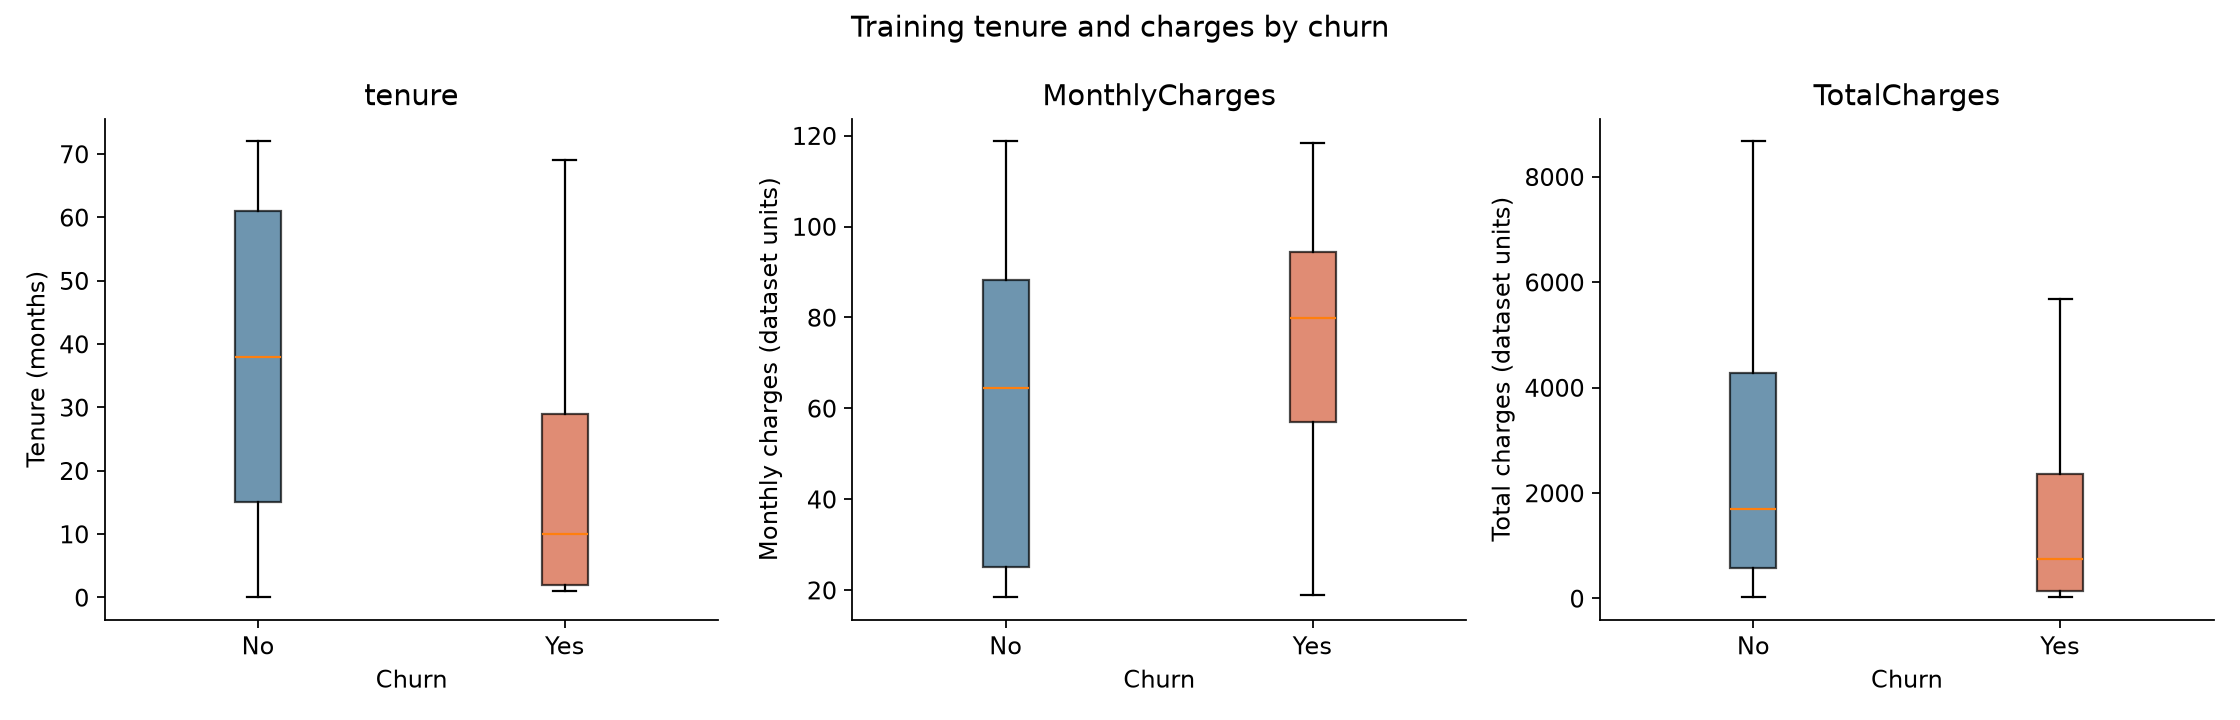

count     mean      std    min     25%      50%  \
Churn feature                                                            
No    tenure          4139.0    37.59    24.14   0.00   15.00    38.00   
      MonthlyCharges  4139.0    61.34    31.14  18.40   25.15    64.40   
      TotalCharges    4131.0  2569.69  2342.74  18.90  576.90  1691.90   
Yes   tenure          1495.0    18.36    19.74   1.00    2.00    10.00   
      MonthlyCharges  1495.0    74.86    24.60  18.85   56.90    79.95   
      TotalCharges    1495.0  1564.59  1908.84  18.85  144.35   740.30   

                          75%      max  
Churn feature                           
No    tenure            61.00    72.00  
      MonthlyCharges    88.18   118.75  
      TotalCharges    4279.98  8672.45  
Yes   tenure            29.00    72.00  
      MonthlyCharges    94.40   118.35  
      TotalCharges    2368.73  8684.80

Training medians by churn label:

- tenure: No = 38.00; Yes = 10.00.
- MonthlyCharges: No = 64.40; Yes = 79.95.
- TotalCharges: No = 1691.90; Yes = 740.30.

These are descriptive associations. TotalCharges also reflects time spent with the service, so it should be interpreted alongside tenure.

In [7]:
by_churn = train.groupby("Churn")[NUMERIC_COLUMNS].describe().stack(level=0, future_stack=True)
by_churn.index.names = ["Churn", "feature"]
by_churn.to_csv(TABLES / "train_numeric_by_churn.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, feature in zip(axes, NUMERIC_COLUMNS):
    groups = [train.loc[train["Churn"].eq(label), feature].dropna() for label in ["No", "Yes"]]
    boxes = ax.boxplot(groups, tick_labels=["No", "Yes"], showfliers=False, patch_artist=True)
    for box, color in zip(boxes["boxes"], COLORS):
        box.set_facecolor(color)
        box.set_alpha(0.7)
    ax.set(xlabel="Churn", ylabel=LABELS[feature], title=feature)
fig.suptitle("Training tenure and charges by churn")
save_figure(fig, "train_numeric_by_churn.png")
display(by_churn.round(2))
medians = train.groupby("Churn")[NUMERIC_COLUMNS].median()
summary = "Training medians by churn label:\n\n"
for feature in NUMERIC_COLUMNS:
    summary += f"- {feature}: No = {medians.loc['No', feature]:.2f}; Yes = {medians.loc['Yes', feature]:.2f}.\n"
display(Markdown(summary + "\nThese are descriptive associations. TotalCharges also reflects time spent with the service, so it should be interpreted alongside tenure."))

## Output checks and limits

The assertions below check aggregate totals and exported tables against the in-memory training summaries. The held-out feature values have not been explored. No missing-value imputation, scaling, feature selection or model fitting has taken place. The fixed split is reproducible, but a single split does not establish how well later models will generalise to other datasets.

In [8]:
assert balance["count"].sum() == len(train)
assert contract["customers"].sum() == len(train)
assert contract["churned"].sum() == y_train.sum()
assert categorical_summary.groupby("feature")["count"].sum().eq(len(train)).all()
assert numeric_summary.loc["TotalCharges", "count"] + blank_charges.sum() == len(train)
assert missing["missing_count"].sum() == blank_charges.sum()
for filename, expected in [
    ("train_churn_balance.csv", balance.reset_index()),
    ("train_contract_churn.csv", contract.reset_index()),
    ("train_numeric_summary.csv", numeric_summary.reset_index()),
    ("train_numeric_by_churn.csv", by_churn.reset_index()),
    ("train_missing_values.csv", missing),
    ("train_categorical_counts.csv", categorical_summary),
    ("split_summary.csv", split_summary),
]:
    pd.testing.assert_frame_equal(pd.read_csv(TABLES / filename), expected, check_dtype=False)
print("Training-only aggregate checks passed: seven tables and four figures.")

Training-only aggregate checks passed: seven tables and four figures.


## Reference

scikit-learn developers (n.d.) *train_test_split*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html (checked 18 October 2026).

Dataset placement and checksum are documented in the repository README.